# EDA — Staffing vs Demand Signals

Joins the staffing counts (labels) with the enriched occupancy features (signals) and explores:
1. **Morning story** — does occupancy drive breakfast staffing?
2. **Afternoon story** — what drives evening staffing? (day-of-week, season, temperature)
3. **Role breakdown** and special-day effects

Goal: understand the relationships well enough to later label each day's demand tier and flag understaffing.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
DATA = Path("../data/prerocessed")

staff = pd.read_csv(DATA / "rota_staffing_counts.csv", parse_dates=["date"])
occ   = pd.read_csv(DATA / "occupancy_enriched.csv", parse_dates=["date"])

print(f"Staffing: {len(staff):,} rows  |  {staff['date'].min().date()} → {staff['date'].max().date()}")
print(f"Occupancy: {len(occ):,} rows  |  {occ['date'].min().date()} → {occ['date'].max().date()}")

Staffing: 8,585 rows  |  2023-12-04 → 2026-04-26
Occupancy: 1,008 rows  |  2023-07-10 → 2026-04-12


In [4]:
# Total headcount per (date, shift) — sum across all roles
daily_shift = (
    staff.groupby(["date", "shift"])
    .agg(total_headcount=("headcount", "sum"))
    .reset_index()
)

# Normalize the occupancy column name (may contain % symbol)
occ_col = [column for column in occ.columns if "occup" in column.lower()][0]
occ = occ.rename(columns={occ_col: "occupancy_pct"})

# Merge (inner join keeps only overlapping dates)
df = daily_shift.merge(occ, on="date", how="inner")
print(f"Merged: {len(df):,} rows  |  {df['date'].nunique()} unique dates")

morning   = df[df["shift"] == "morning"].copy()
afternoon = df[df["shift"] == "afternoon"].copy()
print(f"Morning rows: {len(morning):,}  |  Afternoon rows: {len(afternoon):,}")

Merged: 1,676 rows  |  840 unique dates
Morning rows: 836  |  Afternoon rows: 840


---
## 1. The Big Picture — Occupancy & Staffing Over Time

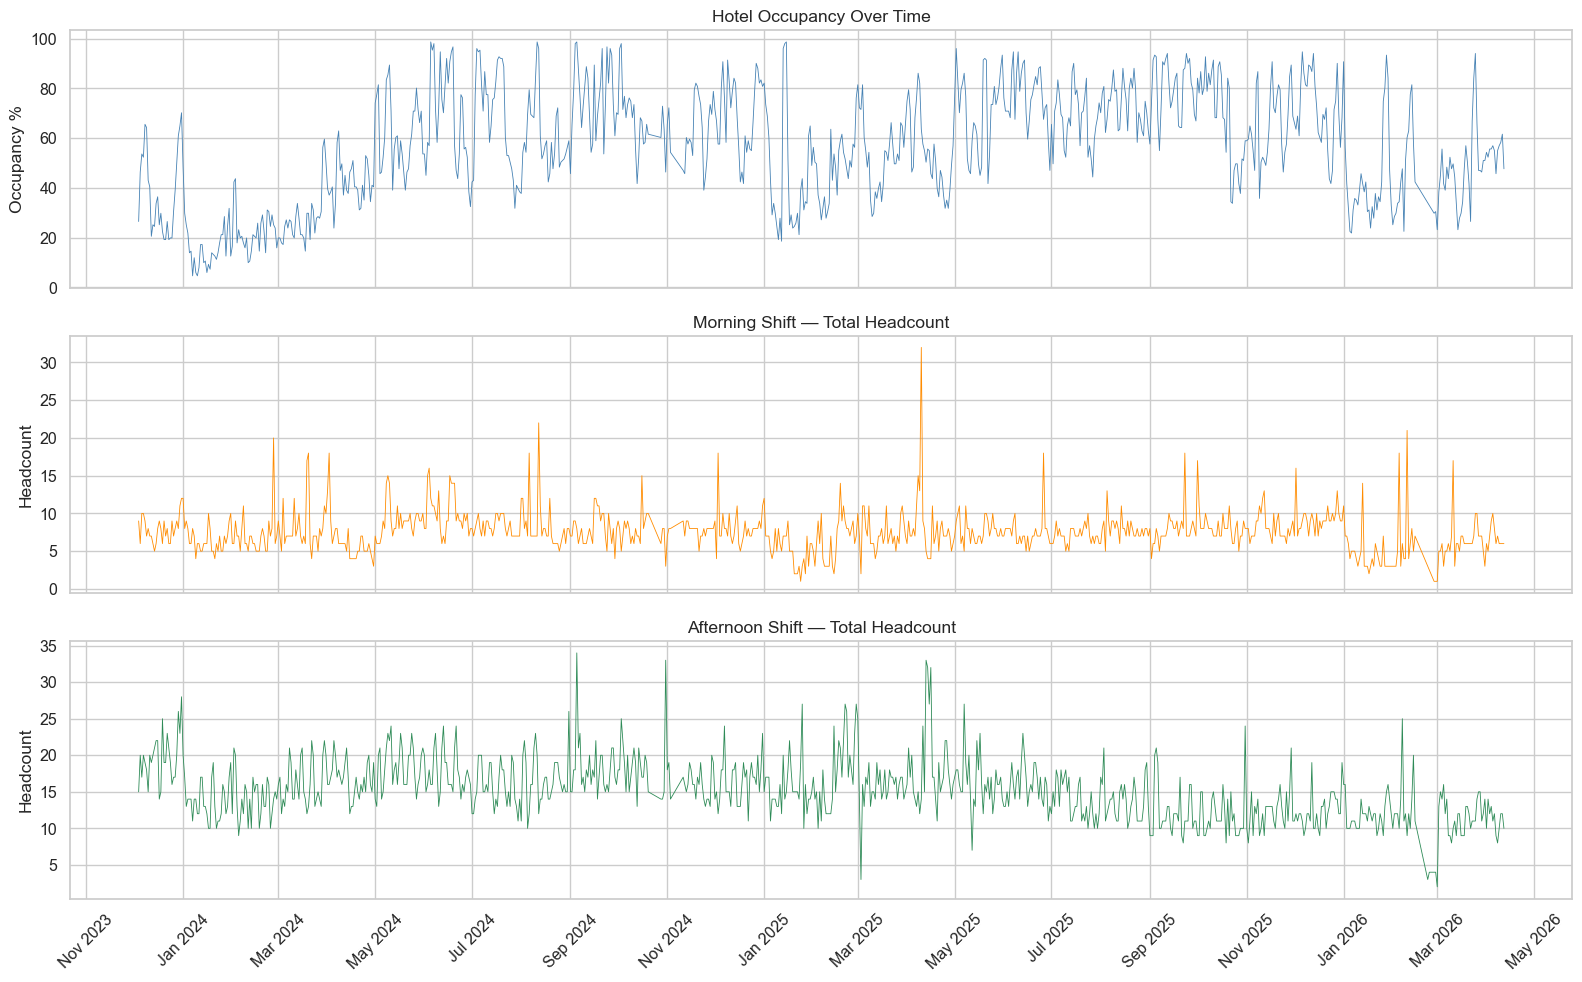

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)

axes[0].plot(morning["date"], morning["occupancy_pct"], linewidth=0.6, color="steelblue")
axes[0].set_ylabel("Occupancy %")
axes[0].set_title("Hotel Occupancy Over Time")

axes[1].plot(morning["date"], morning["total_headcount"], linewidth=0.6, color="darkorange")
axes[1].set_ylabel("Headcount")
axes[1].set_title("Morning Shift — Total Headcount")

axes[2].plot(afternoon["date"], afternoon["total_headcount"], linewidth=0.6, color="seagreen")
axes[2].set_ylabel("Headcount")
axes[2].set_title("Afternoon Shift — Total Headcount")

axes[2].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

---
## 2. Morning Story — Does Occupancy Drive Breakfast Staffing?

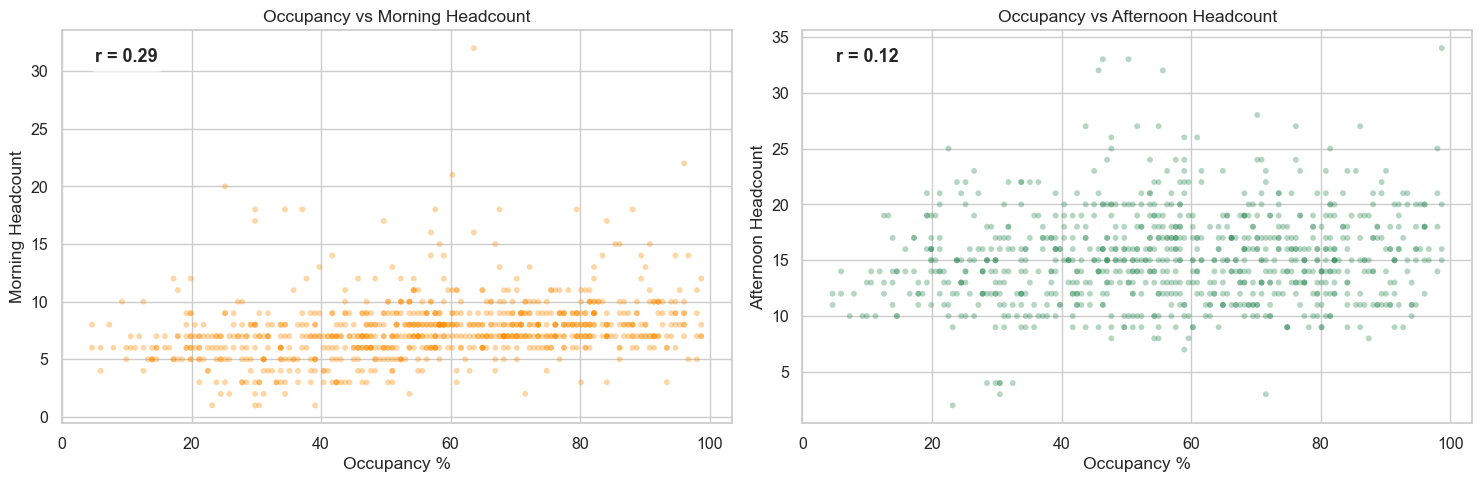

Occupancy → Morning headcount correlation:   r = 0.294
Occupancy → Afternoon headcount correlation: r = 0.124


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(morning["occupancy_pct"], morning["total_headcount"],
                alpha=0.35, s=18, color="darkorange", edgecolors="none")
axes[0].set_xlabel("Occupancy %")
axes[0].set_ylabel("Morning Headcount")
axes[0].set_title("Occupancy vs Morning Headcount")

corr = morning["occupancy_pct"].corr(morning["total_headcount"])
axes[0].annotate(f"r = {corr:.2f}", xy=(0.05, 0.92), xycoords="axes fraction",
                 fontsize=13, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8))

axes[1].scatter(afternoon["occupancy_pct"], afternoon["total_headcount"],
                alpha=0.35, s=18, color="seagreen", edgecolors="none")
axes[1].set_xlabel("Occupancy %")
axes[1].set_ylabel("Afternoon Headcount")
axes[1].set_title("Occupancy vs Afternoon Headcount")

corr_aft = afternoon["occupancy_pct"].corr(afternoon["total_headcount"])
axes[1].annotate(f"r = {corr_aft:.2f}", xy=(0.05, 0.92), xycoords="axes fraction",
                 fontsize=13, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8))

plt.tight_layout()
plt.show()

print(f"Occupancy → Morning headcount correlation:   r = {corr:.3f}")
print(f"Occupancy → Afternoon headcount correlation: r = {corr_aft:.3f}")

---
## 3. Afternoon Story — Day of Week, Season, Temperature

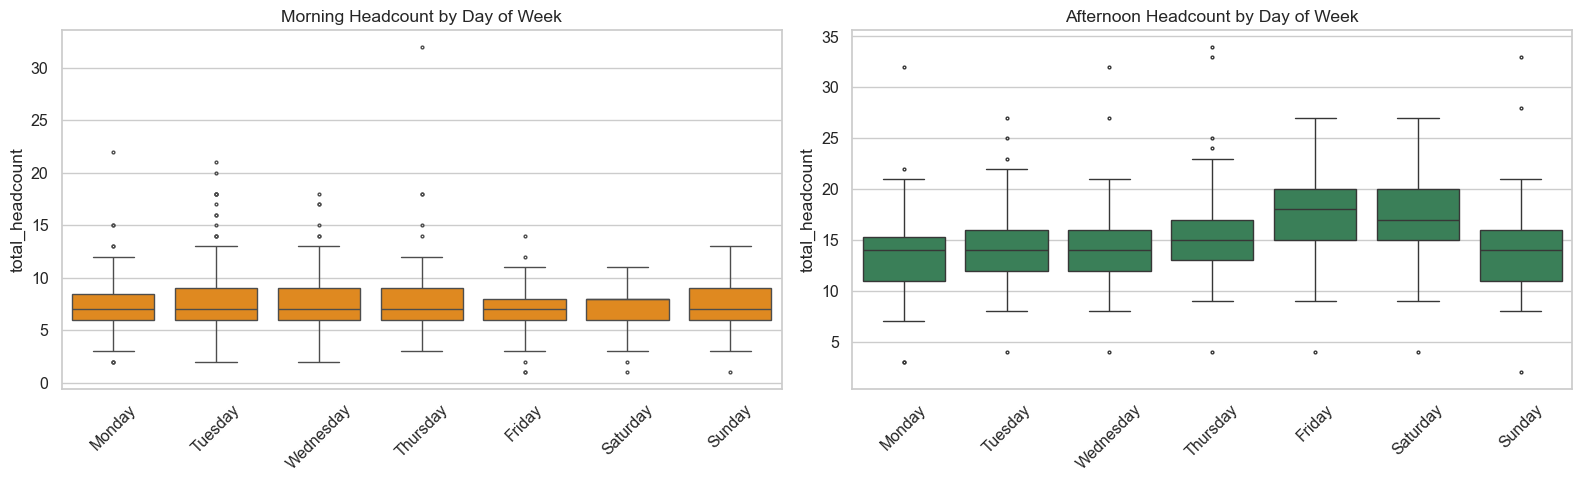

In [5]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data=morning, x="day_name", y="total_headcount",
            order=day_order, ax=axes[0], color="darkorange", fliersize=2)
axes[0].set_title("Morning Headcount by Day of Week")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(data=afternoon, x="day_name", y="total_headcount",
            order=day_order, ax=axes[1], color="seagreen", fliersize=2)
axes[1].set_title("Afternoon Headcount by Day of Week")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

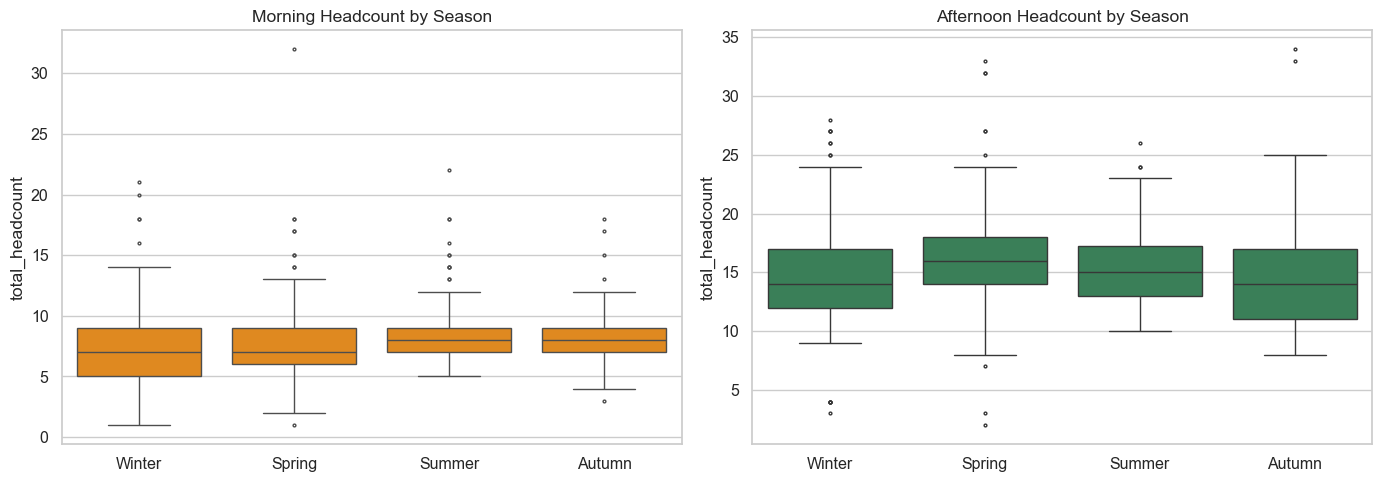

In [6]:
season_order = ["Winter", "Spring", "Summer", "Autumn"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=morning, x="season", y="total_headcount",
            order=season_order, ax=axes[0], color="darkorange", fliersize=2)
axes[0].set_title("Morning Headcount by Season")
axes[0].set_xlabel("")

sns.boxplot(data=afternoon, x="season", y="total_headcount",
            order=season_order, ax=axes[1], color="seagreen", fliersize=2)
axes[1].set_title("Afternoon Headcount by Season")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

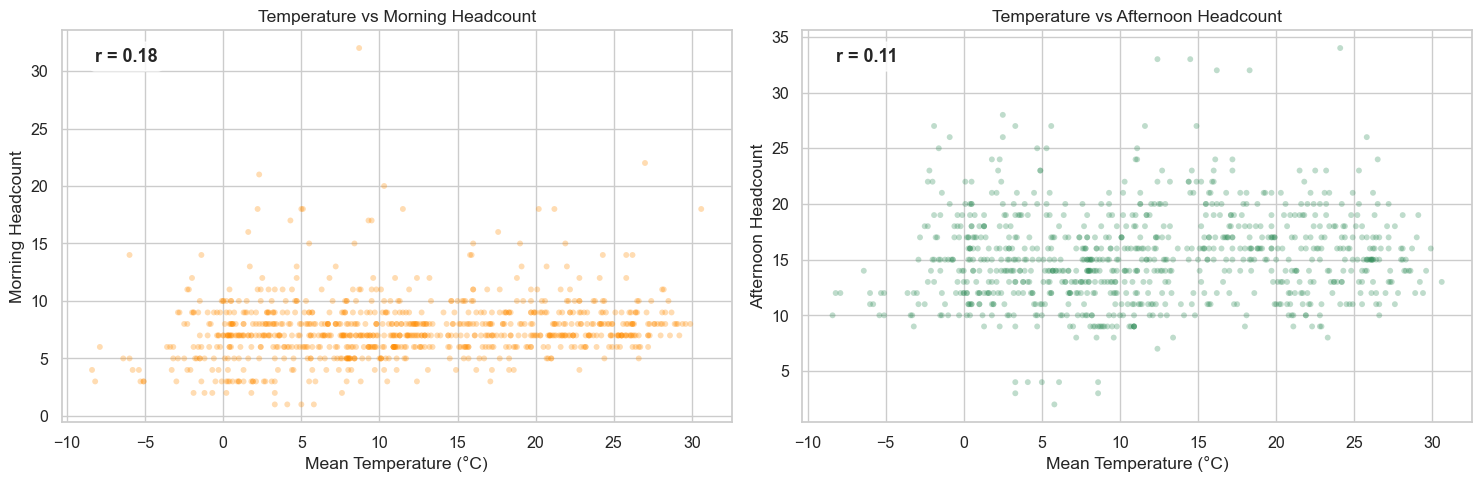

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(morning["temp_mean"], morning["total_headcount"],
                alpha=0.3, s=18, color="darkorange", edgecolors="none")
axes[0].set_xlabel("Mean Temperature (°C)")
axes[0].set_ylabel("Morning Headcount")
axes[0].set_title("Temperature vs Morning Headcount")
r_temp_m = morning["temp_mean"].corr(morning["total_headcount"])
axes[0].annotate(f"r = {r_temp_m:.2f}", xy=(0.05, 0.92), xycoords="axes fraction",
                 fontsize=13, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8))

axes[1].scatter(afternoon["temp_mean"], afternoon["total_headcount"],
                alpha=0.3, s=18, color="seagreen", edgecolors="none")
axes[1].set_xlabel("Mean Temperature (°C)")
axes[1].set_ylabel("Afternoon Headcount")
axes[1].set_title("Temperature vs Afternoon Headcount")
r_temp_a = afternoon["temp_mean"].corr(afternoon["total_headcount"])
axes[1].annotate(f"r = {r_temp_a:.2f}", xy=(0.05, 0.92), xycoords="axes fraction",
                 fontsize=13, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8))

plt.tight_layout()
plt.show()

---
## 4. Role Breakdown — Morning vs Afternoon

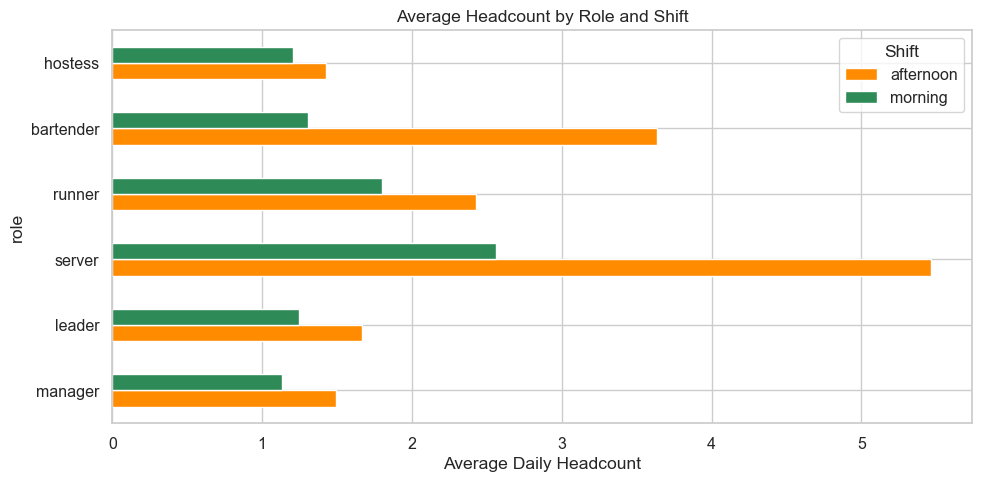

shift,afternoon,morning
role,,
manager,1.5,1.1
leader,1.7,1.2
server,5.5,2.6
runner,2.4,1.8
bartender,3.6,1.3
hostess,1.4,1.2


In [8]:
role_avg = (
    staff.groupby(["shift", "role"])["headcount"]
    .mean()
    .reset_index()
    .pivot(index="role", columns="shift", values="headcount")
    .reindex(["manager", "leader", "server", "runner", "bartender", "hostess"])
)

role_avg.plot(kind="barh", figsize=(10, 5), color=["darkorange", "seagreen"])
plt.xlabel("Average Daily Headcount")
plt.title("Average Headcount by Role and Shift")
plt.legend(title="Shift")
plt.tight_layout()
plt.show()

role_avg.round(1)

---
## 5. Special Days vs Normal Days

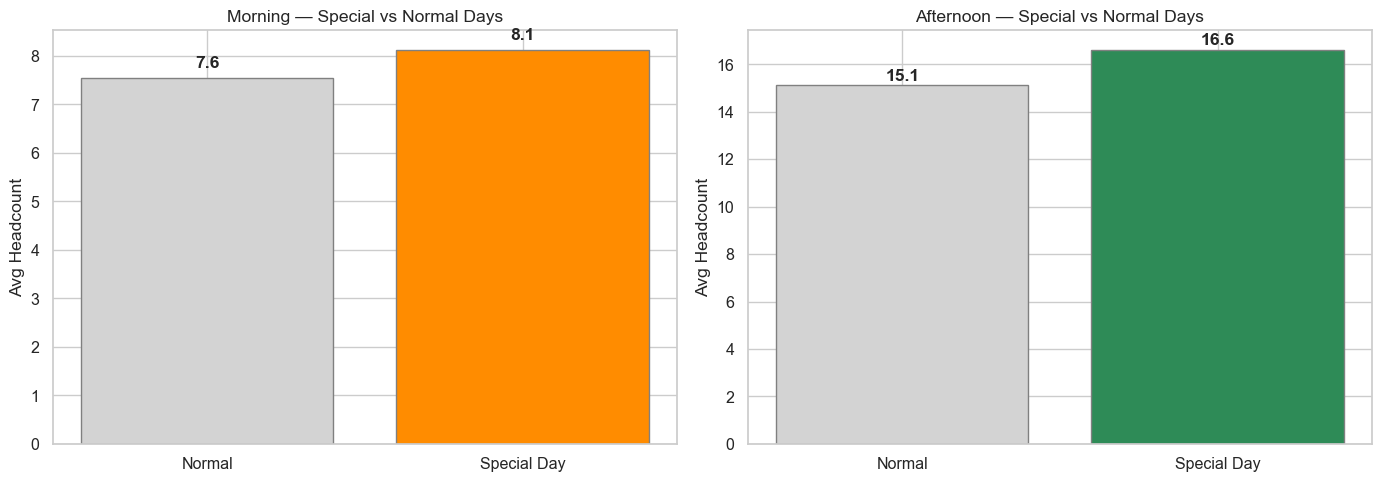

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, shift_df, title, color in [
    (axes[0], morning, "Morning", "darkorange"),
    (axes[1], afternoon, "Afternoon", "seagreen"),
]:
    means = shift_df.groupby("is_special_day")["total_headcount"].mean()
    labels = ["Normal", "Special Day"]
    ax.bar(labels, means.values, color=["lightgray", color], edgecolor="gray")
    ax.set_ylabel("Avg Headcount")
    ax.set_title(f"{title} — Special vs Normal Days")
    for i, v in enumerate(means.values):
        ax.text(i, v + 0.2, f"{v:.1f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

---
## 6. Headcount Distribution — Where Are the Gaps?

These histograms help spot understaffing: if there's a long left tail at low headcounts on high-occupancy days, those are likely understaffed.

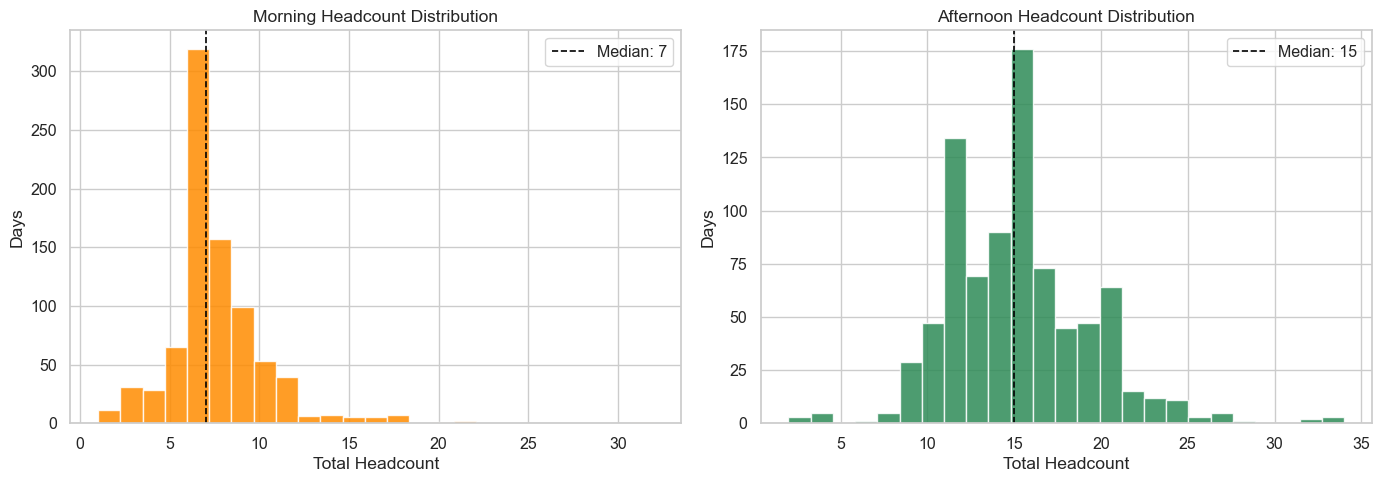

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(morning["total_headcount"], bins=25, color="darkorange", edgecolor="white", alpha=0.85)
axes[0].set_xlabel("Total Headcount")
axes[0].set_ylabel("Days")
axes[0].set_title("Morning Headcount Distribution")
axes[0].axvline(morning["total_headcount"].median(), color="black", ls="--", lw=1.2,
                label=f"Median: {morning['total_headcount'].median():.0f}")
axes[0].legend()

axes[1].hist(afternoon["total_headcount"], bins=25, color="seagreen", edgecolor="white", alpha=0.85)
axes[1].set_xlabel("Total Headcount")
axes[1].set_ylabel("Days")
axes[1].set_title("Afternoon Headcount Distribution")
axes[1].axvline(afternoon["total_headcount"].median(), color="black", ls="--", lw=1.2,
                label=f"Median: {afternoon['total_headcount'].median():.0f}")
axes[1].legend()

plt.tight_layout()
plt.show()

/var/folders/lh/s38phmnd07n2gmlgvdj896rm0000gn/T/ipykernel_48974/884928376.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  morning.groupby(["occ_bucket", "total_headcount"])


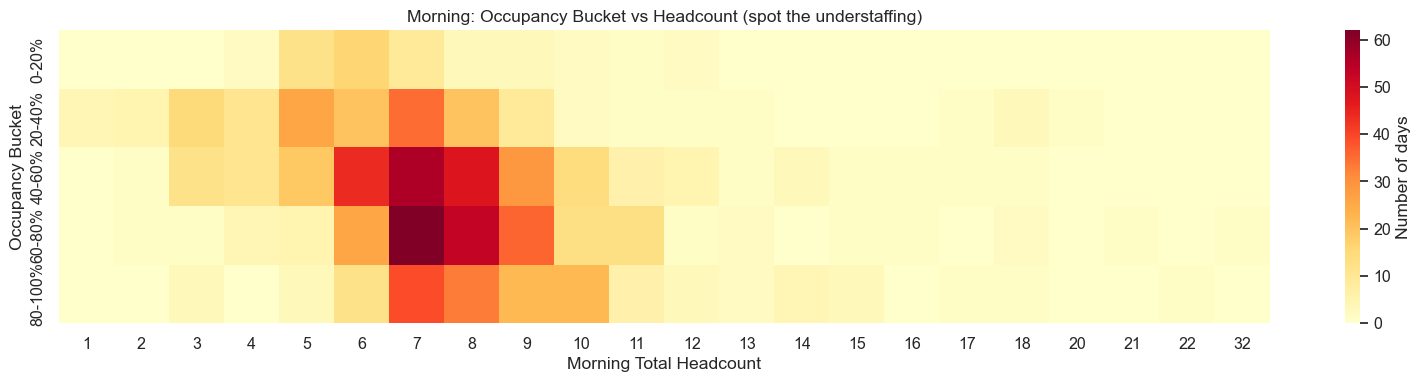

In [11]:
# Heatmap: occupancy bucket vs headcount — helps spot understaffing zones
morning["occ_bucket"] = pd.cut(morning["occupancy_pct"],
                               bins=[0, 20, 40, 60, 80, 100],
                               labels=["0-20%", "20-40%", "40-60%", "60-80%", "80-100%"])

heatmap_data = (
    morning.groupby(["occ_bucket", "total_headcount"])
    .size()
    .unstack(fill_value=0)
)

fig, ax = plt.subplots(figsize=(16, 4))
sns.heatmap(heatmap_data, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Number of days"})
ax.set_xlabel("Morning Total Headcount")
ax.set_ylabel("Occupancy Bucket")
ax.set_title("Morning: Occupancy Bucket vs Headcount (spot the understaffing)")
plt.tight_layout()
plt.show()

---
## 7. Quick Correlation Summary

In [12]:
features = ["occupancy_pct", "day_of_week", "is_weekend", "is_special_day", "temp_mean", "temp_max"]

print("=== Morning headcount correlations ===")
for f in features:
    r = morning[f].corr(morning["total_headcount"])
    print(f"  {f:20s}  r = {r:+.3f}")

print("\n=== Afternoon headcount correlations ===")
for f in features:
    r = afternoon[f].corr(afternoon["total_headcount"])
    print(f"  {f:20s}  r = {r:+.3f}")

=== Morning headcount correlations ===
  occupancy_pct         r = +0.294
  day_of_week           r = -0.084
  is_weekend            r = -0.071
  is_special_day        r = +0.045
  temp_mean             r = +0.177
  temp_max              r = +0.168

=== Afternoon headcount correlations ===
  occupancy_pct         r = +0.124
  day_of_week           r = +0.172
  is_weekend            r = +0.059
  is_special_day        r = +0.078
  temp_mean             r = +0.112
  temp_max              r = +0.109


---
## 7b. Season → Occupancy Relationship

Season drives occupancy, which in turn drives demand. Let's see how occupancy distributes across seasons and days of the week.

/var/folders/lh/s38phmnd07n2gmlgvdj896rm0000gn/T/ipykernel_48974/290675179.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=occ, x="season", y="occupancy_pct",


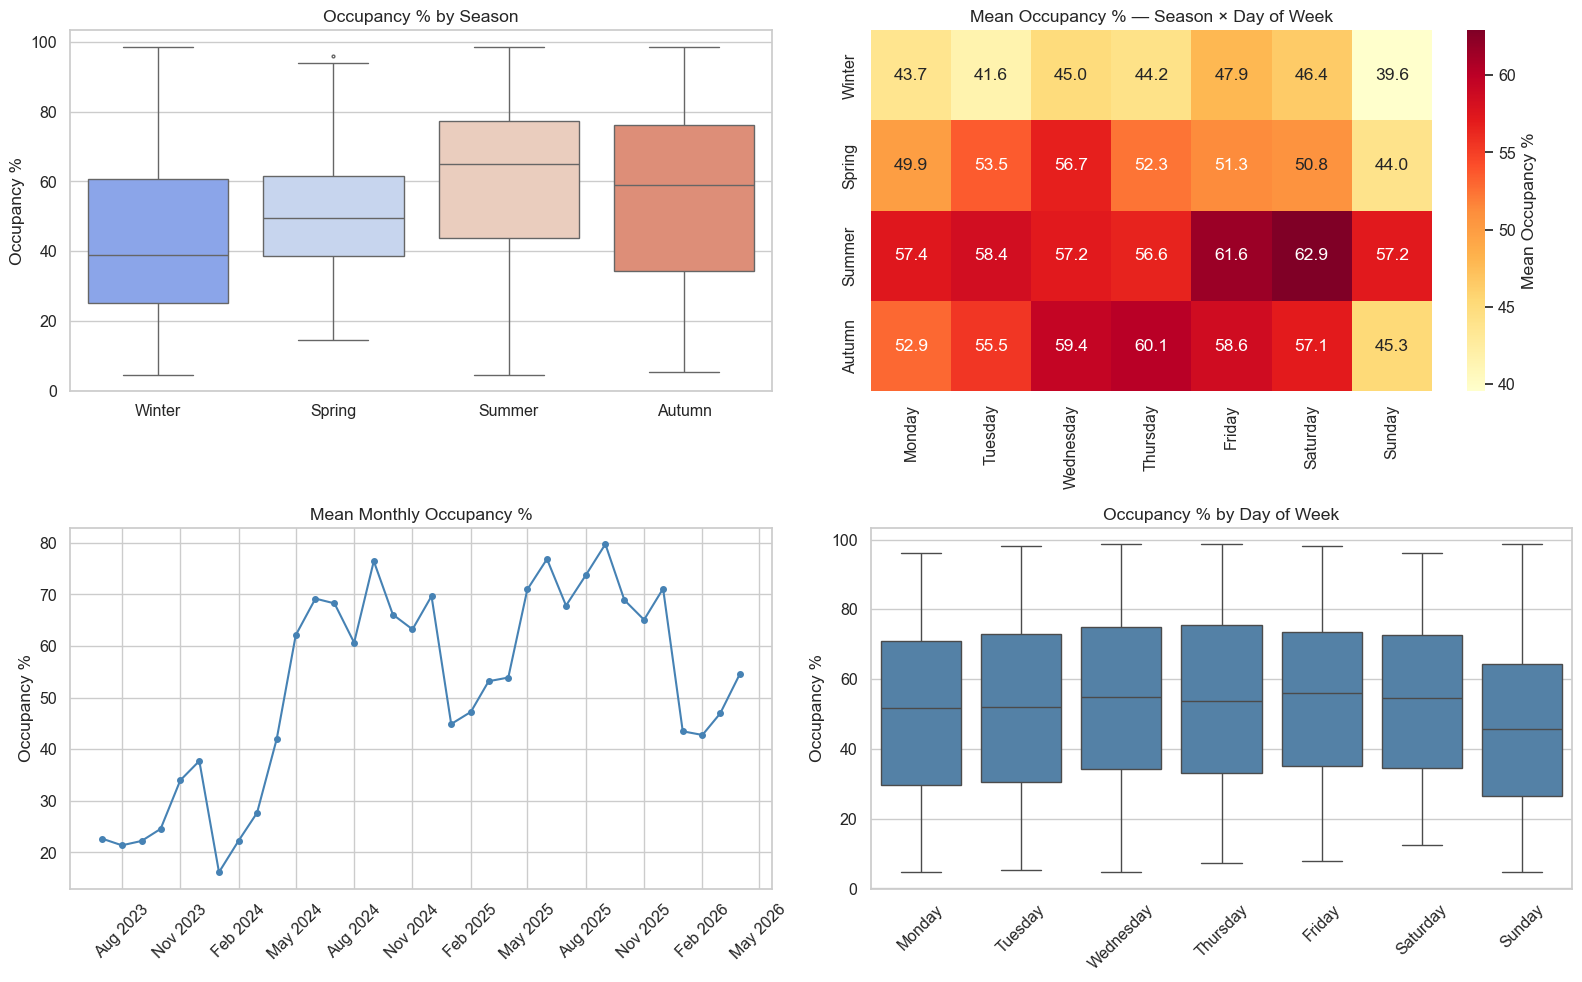

Mean occupancy by season:
  Winter    mean=44.1%  median=39.1%  std=23.4
  Spring    mean=51.2%  median=49.7%  std=18.4
  Summer    mean=58.8%  median=64.9%  std=25.5
  Autumn    mean=55.6%  median=58.9%  std=25.5


In [15]:
season_order = ["Winter", "Spring", "Summer", "Autumn"]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Occupancy by season — boxplot
sns.boxplot(data=occ, x="season", y="occupancy_pct",
            order=season_order, ax=axes[0, 0], palette="coolwarm", fliersize=2)
axes[0, 0].set_title("Occupancy % by Season")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Occupancy %")

# 2. Occupancy by season + day of week — heatmap
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot_occ = occ.pivot_table(index="season", columns="day_name",
                            values="occupancy_pct", aggfunc="mean")
pivot_occ = pivot_occ.reindex(index=season_order, columns=day_order)
sns.heatmap(pivot_occ, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[0, 1],
            cbar_kws={"label": "Mean Occupancy %"})
axes[0, 1].set_title("Mean Occupancy % — Season × Day of Week")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("")

# 3. Monthly occupancy trend
monthly = occ.groupby(occ["date"].dt.to_period("M"))["occupancy_pct"].mean()
monthly.index = monthly.index.to_timestamp()
axes[1, 0].plot(monthly.index, monthly.values, marker="o", markersize=4, color="steelblue")
axes[1, 0].set_title("Mean Monthly Occupancy %")
axes[1, 0].set_ylabel("Occupancy %")
axes[1, 0].tick_params(axis="x", rotation=45)
axes[1, 0].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[1, 0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

# 4. Occupancy by day of week — boxplot
sns.boxplot(data=occ, x="day_name", y="occupancy_pct",
            order=day_order, ax=axes[1, 1], color="steelblue", fliersize=2)
axes[1, 1].set_title("Occupancy % by Day of Week")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Occupancy %")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# Print summary stats
print("Mean occupancy by season:")
for s in season_order:
    vals = occ[occ["season"] == s]["occupancy_pct"]
    print(f"  {s:8s}  mean={vals.mean():.1f}%  median={vals.median():.1f}%  std={vals.std():.1f}")

---
## 8. Multivariate Analysis — Features Combined

Individual correlations were weak because they measure each signal in isolation.
A Random Forest sees all features *together* — "Saturday + Summer + 80% occupancy" is a
very different input than "Saturday + Winter + 25% occupancy."

This section answers: **how much of the human scheduler's decisions can be explained
when we consider all signals at once?** The low R² itself is evidence for the thesis:
the static approach ignores available demand signals.

In [13]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
import numpy as np

feature_cols = ["occupancy_pct", "day_of_week", "is_weekend", "is_special_day",
                "temp_mean", "temp_max"]

# Encode season as dummies (tree models handle this, but it helps interpretability)
season_dummies = pd.get_dummies(df["season"], prefix="season", drop_first=True)
X_base = df[feature_cols].join(season_dummies)

results = {}
for label, shift_mask in [("morning", df["shift"] == "morning"),
                           ("afternoon", df["shift"] == "afternoon")]:
    X = X_base.loc[shift_mask].copy()
    y = df.loc[shift_mask, "total_headcount"].copy()

    # Drop any rows with NaN
    valid = X.notna().all(axis=1) & y.notna()
    X, y = X[valid], y[valid]

    rf = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)
    scores = cross_val_score(rf, X, y, cv=5, scoring="r2")

    # Fit on full data for feature importances
    rf.fit(X, y)

    results[label] = {
        "r2_cv": scores,
        "importances": pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False),
    }

    best_single_r = max(abs(df.loc[shift_mask, f].corr(y)) for f in feature_cols)

    print(f"=== {label.upper()} SHIFT ===")
    print(f"  Best single-feature r:      {best_single_r:.3f}  (r² = {best_single_r**2:.3f})")
    print(f"  Random Forest combined R²:   {scores.mean():.3f}  (±{scores.std():.3f}, 5-fold CV)")
    print(f"  Improvement factor:          {scores.mean() / best_single_r**2:.1f}x")
    print()

=== MORNING SHIFT ===
  Best single-feature r:      0.294  (r² = 0.087)
  Random Forest combined R²:   -0.211  (±0.271, 5-fold CV)
  Improvement factor:          -2.4x

=== AFTERNOON SHIFT ===
  Best single-feature r:      0.172  (r² = 0.030)
  Random Forest combined R²:   -0.916  (±0.776, 5-fold CV)
  Improvement factor:          -31.0x



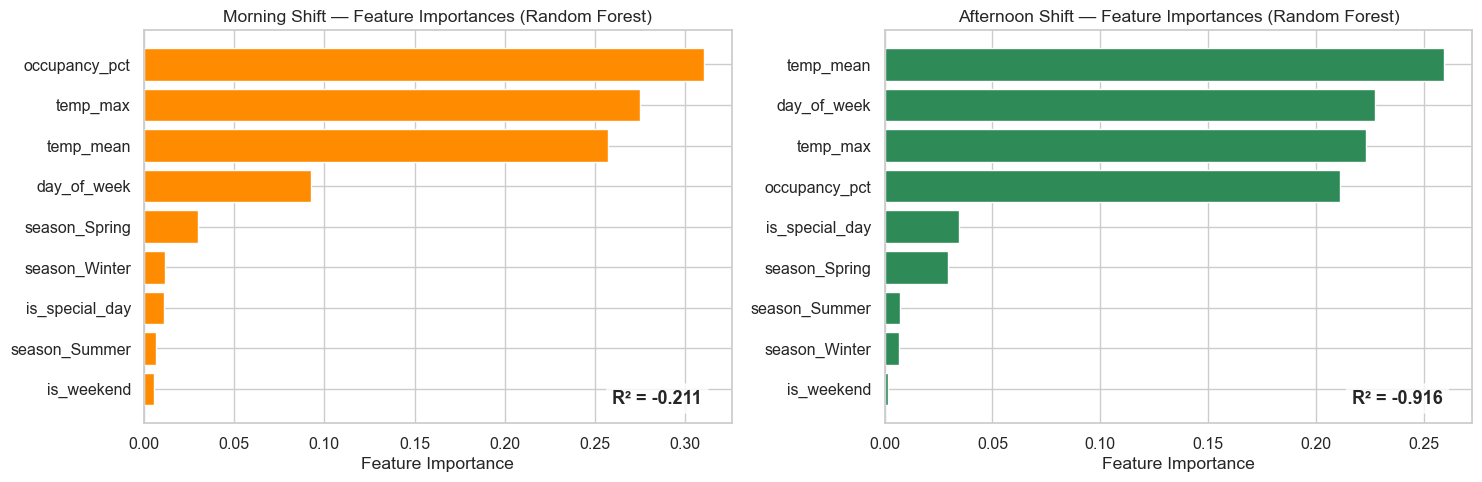

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, (label, color) in zip(axes, [("morning", "darkorange"), ("afternoon", "seagreen")]):
    imp = results[label]["importances"]
    ax.barh(imp.index[::-1], imp.values[::-1], color=color, edgecolor="white")
    ax.set_xlabel("Feature Importance") 
    ax.set_title(f"{label.title()} Shift — Feature Importances (Random Forest)")
    r2 = results[label]["r2_cv"].mean()
    ax.annotate(f"R² = {r2:.3f}", xy=(0.95, 0.05), xycoords="axes fraction",
                ha="right", fontsize=13, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8))

plt.tight_layout()
plt.show()

---
## 9. Export Figures for Thesis

Saves publication-quality versions of key charts to `thesis/figures/`.

In [ ]:
FIG_DIR = Path("../thesis/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
DPI = 200

# --- Fig 1: Time series (occupancy + morning + afternoon headcount) ---
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
axes[0].plot(morning["date"], morning["occupancy_pct"], linewidth=0.6, color="steelblue")
axes[0].set_ylabel("Occupancy %")
axes[0].set_title("Hotel Occupancy Over Time")
axes[1].plot(morning["date"], morning["total_headcount"], linewidth=0.6, color="darkorange")
axes[1].set_ylabel("Headcount")
axes[1].set_title("Morning Shift — Total Headcount")
axes[2].plot(afternoon["date"], afternoon["total_headcount"], linewidth=0.6, color="seagreen")
axes[2].set_ylabel("Headcount")
axes[2].set_title("Afternoon Shift — Total Headcount")
axes[2].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
plt.tight_layout()
fig.savefig(FIG_DIR / "eda_timeseries.png", dpi=DPI, bbox_inches="tight")
plt.show()
print("Saved eda_timeseries.png")

# --- Fig 2: Scatter — occupancy vs headcount (morning + afternoon) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(morning["occupancy_pct"], morning["total_headcount"],
                alpha=0.35, s=18, color="darkorange", edgecolors="none")
axes[0].set_xlabel("Occupancy %"); axes[0].set_ylabel("Morning Headcount")
axes[0].set_title("Occupancy vs Morning Headcount")
corr_m = morning["occupancy_pct"].corr(morning["total_headcount"])
axes[0].annotate(f"r = {corr_m:.2f}", xy=(0.05, 0.92), xycoords="axes fraction",
                 fontsize=13, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8))
axes[1].scatter(afternoon["occupancy_pct"], afternoon["total_headcount"],
                alpha=0.35, s=18, color="seagreen", edgecolors="none")
axes[1].set_xlabel("Occupancy %"); axes[1].set_ylabel("Afternoon Headcount")
axes[1].set_title("Occupancy vs Afternoon Headcount")
corr_a = afternoon["occupancy_pct"].corr(afternoon["total_headcount"])
axes[1].annotate(f"r = {corr_a:.2f}", xy=(0.05, 0.92), xycoords="axes fraction",
                 fontsize=13, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8))
plt.tight_layout()
fig.savefig(FIG_DIR / "eda_scatter_occupancy.png", dpi=DPI, bbox_inches="tight")
plt.show()
print("Saved eda_scatter_occupancy.png")

# --- Fig 3: Day-of-week boxplots ---
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=morning, x="day_name", y="total_headcount",
            order=day_order, ax=axes[0], color="darkorange", fliersize=2)
axes[0].set_title("Morning Headcount by Day of Week"); axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=45)
sns.boxplot(data=afternoon, x="day_name", y="total_headcount",
            order=day_order, ax=axes[1], color="seagreen", fliersize=2)
axes[1].set_title("Afternoon Headcount by Day of Week"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
fig.savefig(FIG_DIR / "eda_boxplot_dayofweek.png", dpi=DPI, bbox_inches="tight")
plt.show()
print("Saved eda_boxplot_dayofweek.png")

# --- Fig 4: Feature importance (Random Forest) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (label, color) in zip(axes, [("morning", "darkorange"), ("afternoon", "seagreen")]):
    imp = results[label]["importances"]
    ax.barh(imp.index[::-1], imp.values[::-1], color=color, edgecolor="white")
    ax.set_xlabel("Feature Importance")
    ax.set_title(f"{label.title()} Shift — Feature Importances (Random Forest)")
    r2 = results[label]["r2_cv"].mean()
    ax.annotate(f"R² = {r2:.3f}", xy=(0.95, 0.05), xycoords="axes fraction",
                ha="right", fontsize=13, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8))
plt.tight_layout()
fig.savefig(FIG_DIR / "eda_feature_importance.png", dpi=DPI, bbox_inches="tight")
plt.show()
print("Saved eda_feature_importance.png")

# --- Fig 5: Heatmap — occupancy bucket vs headcount ---
if "occ_bucket" not in morning.columns:
    morning["occ_bucket"] = pd.cut(morning["occupancy_pct"],
                                   bins=[0, 20, 40, 60, 80, 100],
                                   labels=["0-20%", "20-40%", "40-60%", "60-80%", "80-100%"])
heatmap_data = morning.groupby(["occ_bucket", "total_headcount"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(heatmap_data, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Number of days"})
ax.set_xlabel("Morning Total Headcount"); ax.set_ylabel("Occupancy Bucket")
ax.set_title("Morning: Occupancy Bucket vs Headcount")
plt.tight_layout()
fig.savefig(FIG_DIR / "eda_heatmap_understaffing.png", dpi=DPI, bbox_inches="tight")
plt.show()
print("Saved eda_heatmap_understaffing.png")

print(f"\nAll figures saved to {FIG_DIR.resolve()}")